# Exploratory Data Analysis (EDA)

In this section we explore the dataset to understand the structure of the data and look for patterns that might help predict whether a car will break down within 30 days.

The goal of this analysis is to:
- understand the variables in the dataset
- check for missing values
- analyse the distribution of the target variable
- explore relationships between features and breakdowns

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
train = pd.read_csv("../train_CarBreakDown.csv")

train.head()

,id,vehicle_brand,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,weather_exposure,fuel_type,cleanliness_score,driver_satisfaction_score,tyre_type,breakdown_next_30_days
0,959,Toyota,20.0,494744.972722,9700.481467,1672.048445,61.664556,30.362090,high,petrol,68.117833,8.559011,NaN,0
1,804,Toyota,0.0,38376.684834,1650.726428,21.269170,23.370666,2.500801,high,hybrid,69.294736,9.838274,NaN,0
2,1304,Hyundai,1.0,188558.432414,6678.958321,11726.320455,25.491428,41.692205,medium,hybrid,47.223966,5.842726,winter,0
3,268,Toyota,5.0,92828.113285,2986.923461,1845.744691,54.060416,6.464345,high,diesel,72.246829,4.719607,winter,0
4,47,NaN,10.0,118366.394287,4222.193011,12551.181627,65.766074,47.159242,low,diesel,77.368891,6.724967,winter,0


In [7]:
print("Shape of dataset:", train.shape)
print()

print("Column names:")
print(train.columns)
print()

print("Data types:")
print(train.dtypes)

Shape of dataset: (1050, 14)

Column names:
Index(['id', 'vehicle_brand', 'vehicle_age_years', 'mileage_km',
       'engine_hours', 'last_service_km_ago', 'oil_quality_pct',
       'avg_trip_length_km', 'weather_exposure', 'fuel_type',
       'cleanliness_score', 'driver_satisfaction_score', 'tyre_type',
       'breakdown_next_30_days'],
      dtype='str')

Data types:
id                             int64
vehicle_brand                    str
vehicle_age_years            float64
mileage_km                   float64
engine_hours                 float64
last_service_km_ago          float64
oil_quality_pct              float64
avg_trip_length_km           float64
weather_exposure                 str
fuel_type                        str
cleanliness_score            float64
driver_satisfaction_score    float64
tyre_type                        str
breakdown_next_30_days         int64
dtype: object


In [8]:
print("Missing values per column:")
print(train.isnull().sum())

Missing values per column:
id                            0
vehicle_brand                21
vehicle_age_years            16
mileage_km                   17
engine_hours                 15
last_service_km_ago          10
oil_quality_pct              36
avg_trip_length_km           12
weather_exposure             13
fuel_type                    14
cleanliness_score            55
driver_satisfaction_score    13
tyre_type                    17
breakdown_next_30_days        0
dtype: int64


In [9]:
train["breakdown_next_30_days"].value_counts()

breakdown_next_30_days
0    874
1    176
Name: count, dtype: int64

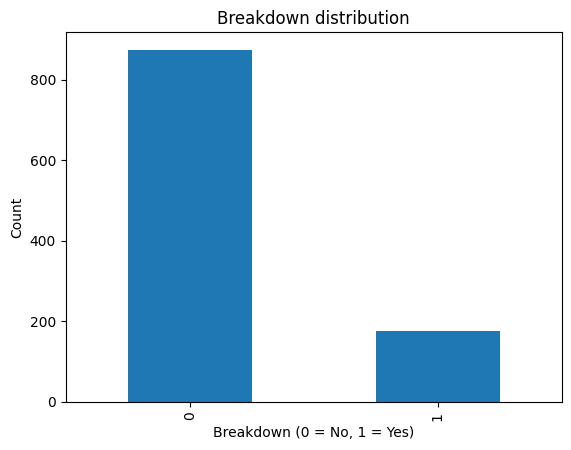

In [10]:
train["breakdown_next_30_days"].value_counts().plot(kind="bar")

plt.title("Breakdown distribution")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

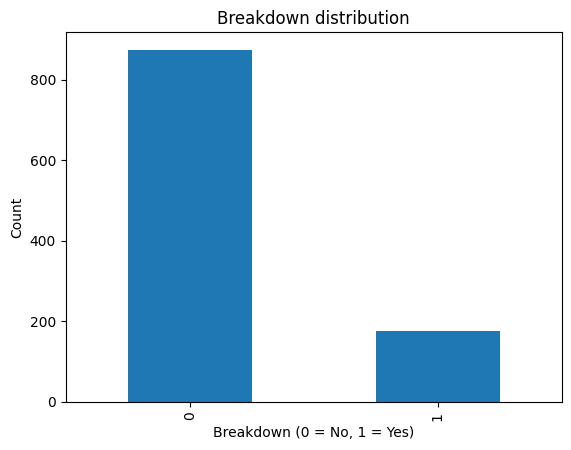

In [11]:
train["breakdown_next_30_days"].value_counts().plot(kind="bar")

plt.title("Breakdown distribution")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

In [12]:
brand_breakdown = train.groupby("vehicle_brand")["breakdown_next_30_days"].mean()

brand_breakdown.sort_values(ascending=False)

vehicle_brand
other         0.214286
Volvo         0.204301
Ford          0.190722
BMW           0.184000
Toyota        0.181347
Renault       0.164948
Volkswagen    0.139860
Kia           0.101449
Hyundai       0.099010
Name: breakdown_next_30_days, dtype: float64

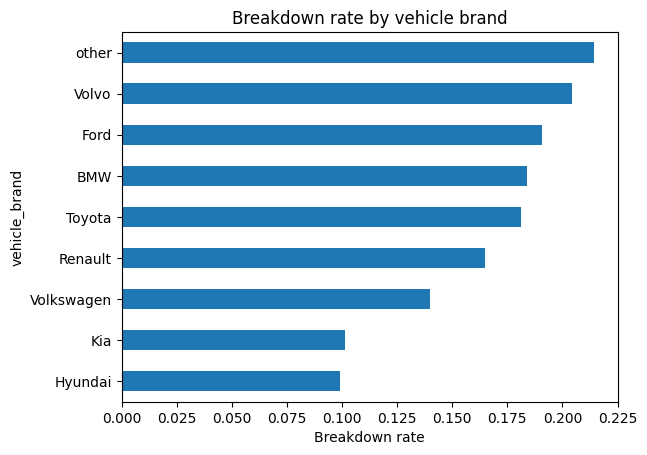

In [13]:
brand_breakdown.sort_values().plot(kind="barh")

plt.title("Breakdown rate by vehicle brand")
plt.xlabel("Breakdown rate")

plt.show()

In [14]:
fuel_breakdown = train.groupby("fuel_type")["breakdown_next_30_days"].mean()

fuel_breakdown

fuel_type
diesel      0.166667
electric    0.185185
hybrid      0.161290
other       0.150000
petrol      0.174713
Name: breakdown_next_30_days, dtype: float64

In [15]:
weather_breakdown = train.groupby("weather_exposure")["breakdown_next_30_days"].mean()

weather_breakdown

weather_exposure
high      0.200980
low       0.174479
medium    0.149533
other     0.142857
Name: breakdown_next_30_days, dtype: float64

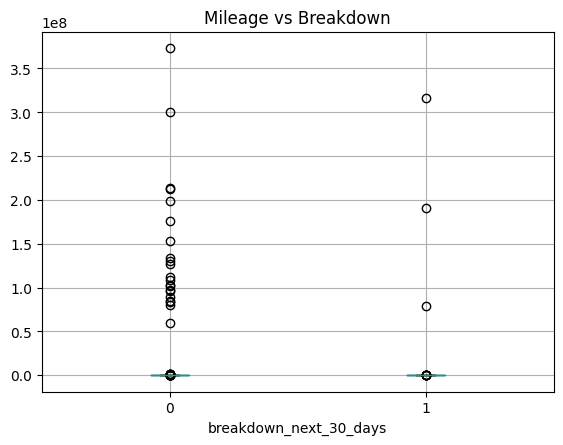

In [16]:
train.boxplot(column="mileage_km", by="breakdown_next_30_days")

plt.title("Mileage vs Breakdown")
plt.suptitle("")

plt.show()

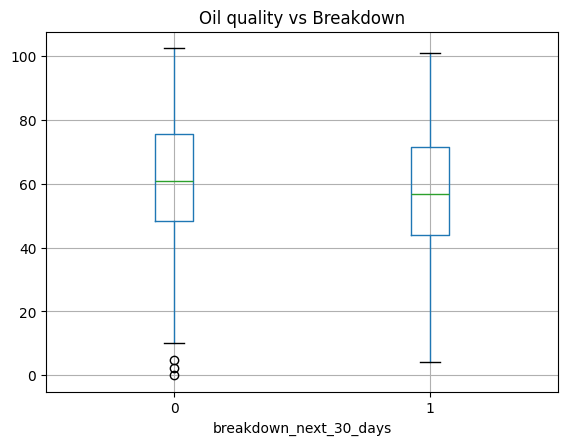

In [17]:
train.boxplot(column="oil_quality_pct", by="breakdown_next_30_days")

plt.title("Oil quality vs Breakdown")
plt.suptitle("")

plt.show()

In [18]:
correlation = train.corr(numeric_only=True)

correlation

,id,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,cleanliness_score,driver_satisfaction_score,breakdown_next_30_days
id,1.000000,-0.013399,-0.035830,-0.001577,0.018367,-0.036700,0.012493,0.003179,0.038817,-0.039711
vehicle_age_years,-0.013399,1.000000,-0.002210,0.015299,0.040071,0.016606,0.042474,0.025936,0.005639,0.138214
mileage_km,-0.035830,-0.002210,1.000000,0.114152,0.060717,0.036886,-0.034124,-0.027715,-0.055603,-0.003028
engine_hours,-0.001577,0.015299,0.114152,1.000000,-0.031101,0.022425,-0.031955,-0.013603,0.066042,0.053000
last_service_km_ago,0.018367,0.040071,0.060717,-0.031101,1.000000,0.043297,0.046232,0.008769,0.004347,0.067742
oil_quality_pct,-0.036700,0.016606,0.036886,0.022425,0.043297,1.000000,-0.012404,0.017318,-0.019642,-0.083499
avg_trip_length_km,0.012493,0.042474,-0.034124,-0.031955,0.046232,-0.012404,1.000000,0.019428,0.028570,-0.013303
cleanliness_score,0.003179,0.025936,-0.027715,-0.013603,0.008769,0.017318,0.019428,1.000000,-0.004824,-0.027467
driver_satisfaction_score,0.038817,0.005639,-0.055603,0.066042,0.004347,-0.019642,0.028570,-0.004824,1.000000,0.015899
breakdown_next_30_days,-0.039711,0.138214,-0.003028,0.053000,0.067742,-0.083499,-0.013303,-0.027467,0.015899,1.000000


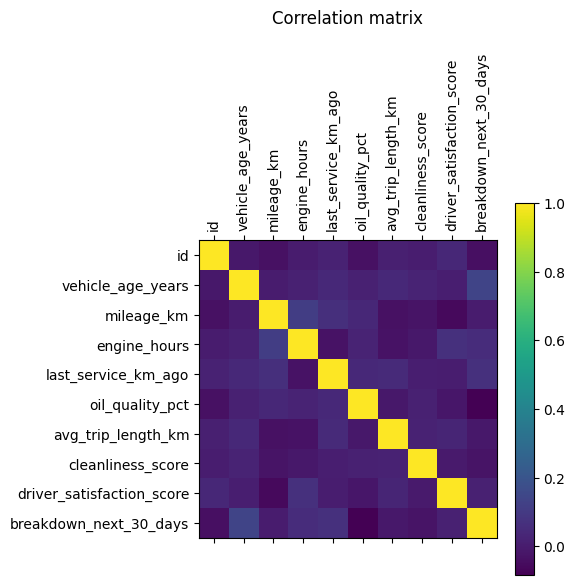

In [19]:
plt.matshow(correlation)

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.colorbar()

plt.title("Correlation matrix", pad=20)

plt.show()

## Observations

From the exploratory data analysis we can observe several things:

- The dataset contains information about vehicle characteristics such as mileage, engine hours, oil quality and maintenance history.
- The target variable `breakdown_next_30_days` indicates whether a breakdown occurred.
- Some variables such as mileage and oil quality appear to show differences between cars that break down and those that do not.
- Environmental exposure and maintenance history might also influence the probability of a breakdown.

This analysis helps us understand the dataset before building machine learning models.